In [1]:
# Celda 1 — Bootstrap: conecta el notebook con Django para usar los modelos y la base de datos.
import os
import sys

sys.path.append(os.path.abspath(".."))  # raíz de backend/
os.environ.setdefault("DJANGO_SETTINGS_MODULE", "config.settings")
os.environ["DJANGO_ALLOW_ASYNC_UNSAFE"] = "true"

import django
django.setup()

In [2]:
# Celda 2 — Carga todas las tasas de TasaInteresMercado en una tabla ancha (una fila por mes, una columna
# por serie, 1982-2026) y agrega la inflación 12 meses calculada desde la UF del día 9 de cada mes.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_engine.models import IndicadorEconomico, TasaInteresMercado
from data_engine.models.indicador_economico import Indicador

crudo = pd.DataFrame(TasaInteresMercado.objects.values("fecha", "nombre", "tipo", "valor"))
crudo["valor"] = crudo["valor"].astype(float)
crudo["fecha"] = pd.to_datetime(crudo["fecha"])
# La TPM tiene dos tipos (real hasta 2001, nominal después): se separan en dos columnas
crudo["serie"] = np.where(crudo["nombre"] == "Tasa de política monetaria",
                          "TPM " + crudo["tipo"], crudo["nombre"])
tasas = crudo.pivot(index="fecha", columns="serie", values="valor").asfreq("MS")

# Inflación 12 meses desde la UF: la UF del día 9 del mes m+1 refleja el IPC del mes m-1.
# Por eso la inflación del mes k = UF(9 de k+2) / UF(9 de k-10) - 1.
uf = pd.DataFrame(IndicadorEconomico.objects.filter(indicador=Indicador.UF, fecha__day=9)
                  .values("fecha", "valor"))
uf["fecha"] = pd.to_datetime(uf["fecha"]).dt.to_period("M").dt.to_timestamp()
uf = uf.set_index("fecha")["valor"].astype(float).asfreq("MS")
tasas["Inflación 12m"] = (uf.shift(-2) / uf.shift(10) - 1) * 100

print(tasas.shape, "|", tasas.index.min().date(), "→", tasas.index.max().date())
tasas.notna().sum().sort_values(ascending=False)

(537, 26) | 1982-01-01 → 2026-09-01


serie
Captación en pesos, 30 a 89 días       537
Captación en UF, 90 días a 1 año       537
Inflación 12m                          537
Captación en pesos, 90 días a 1 año    501
Captación en UF, 1 a 3 años            441
Captación en pesos, 1 a 3 años         441
Captación en UF, más de 3 años         387
TPM nominal                            301
Captación en pesos, más de 3 años      295
Bono en UF a 10 años                   289
Bono en UF a 20 años                   287
Bono en pesos a 5 años                 280
Bono en UF a 5 años                    280
Bono en pesos a 2 años                 270
Bono en pesos a 10 años                267
Bono en pesos a 1 año                  240
Bono en UF a 2 años                    227
Bono en UF a 30 años                   222
Bono en UF a 1 año                     205
PRBC en UF a 90 días                   174
PRC en UF a 8 años                     124
PRC en UF a 20 años                    114
PRC en UF a 10 años                    111
PRC e

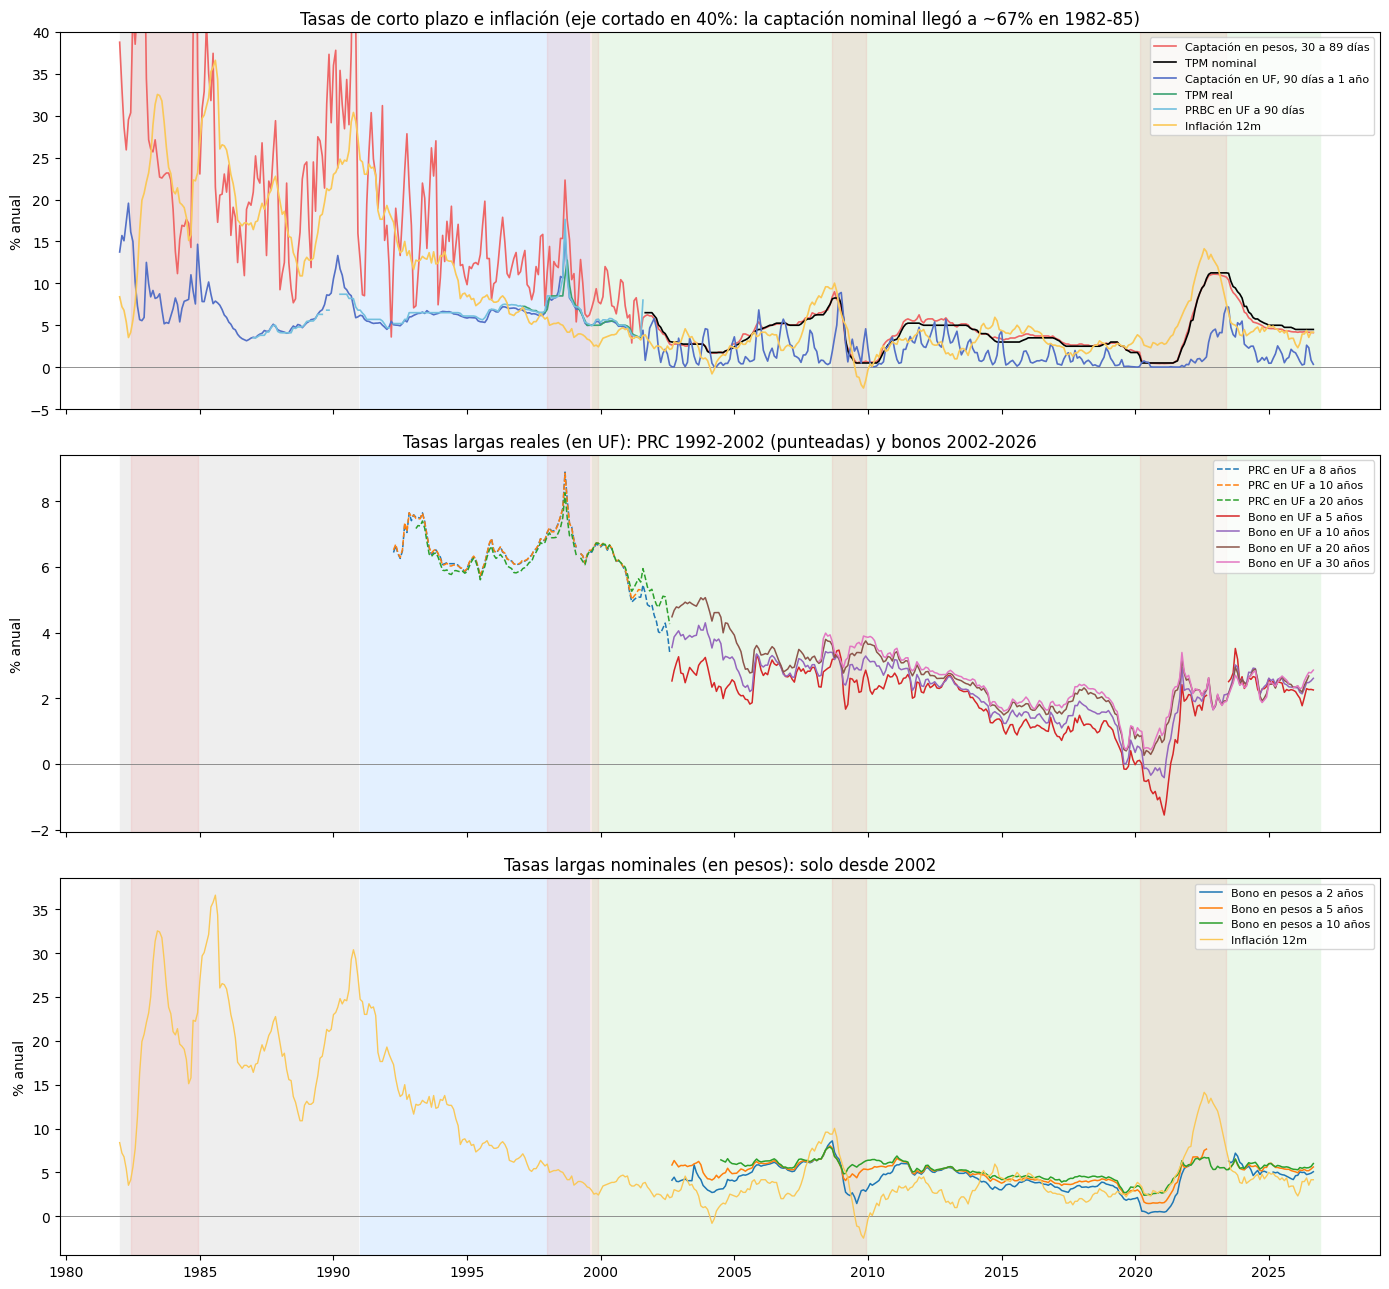

In [4]:
# Celda 3 — Gráfico de toda la historia en tres paneles: (1) tasas cortas e inflación,
# (2) tasas largas reales (PRC y bonos en UF), (3) tasas largas nominales (bonos en pesos).
# Fondo: regímenes monetarios (sin meta, metas parciales, metas plenas). Franjas rojas: crisis.
REGIMENES = [("1982-01", "1990-12", "#eeeeee", "sin meta"),
             ("1991-01", "1999-08", "#e3f0ff", "metas parciales"),
             ("1999-09", "2026-12", "#e9f7e9", "metas plenas")]
CRISIS = [("1982-06", "1984-12"), ("1998-01", "1999-12"), ("2008-09", "2009-12"), ("2020-03", "2023-06")]


def fondo(ax):
    for desde, hasta, color, _ in REGIMENES:
        ax.axvspan(pd.Timestamp(desde), pd.Timestamp(hasta), color=color, zorder=0)
    for desde, hasta in CRISIS:
        ax.axvspan(pd.Timestamp(desde), pd.Timestamp(hasta), color="#ee6666", alpha=0.12, zorder=0)
    ax.axhline(0, color="gray", linewidth=0.6)


fig, axes = plt.subplots(3, 1, figsize=(14, 13), sharex=True)

ax = axes[0]
fondo(ax)
for serie, color in [("Captación en pesos, 30 a 89 días", "#ee6666"), ("TPM nominal", "#000000"),
                     ("Captación en UF, 90 días a 1 año", "#5470c6"), ("TPM real", "#3ba272"),
                     ("PRBC en UF a 90 días", "#73c0de"), ("Inflación 12m", "#fac858")]:
    ax.plot(tasas.index, tasas[serie], label=serie, color=color, linewidth=1.2)
ax.set_ylim(-5, 40)
ax.set_title("Tasas de corto plazo e inflación (eje cortado en 40%: la captación nominal llegó a ~67% en 1982-85)")
ax.legend(loc="upper right", fontsize=8)

ax = axes[1]
fondo(ax)
for serie in ["PRC en UF a 8 años", "PRC en UF a 10 años", "PRC en UF a 20 años",
              "Bono en UF a 5 años", "Bono en UF a 10 años", "Bono en UF a 20 años", "Bono en UF a 30 años"]:
    ax.plot(tasas.index, tasas[serie], label=serie, linewidth=1.1,
            linestyle="--" if serie.startswith("PRC") else "-")
ax.set_title("Tasas largas reales (en UF): PRC 1992-2002 (punteadas) y bonos 2002-2026")
ax.legend(loc="upper right", fontsize=8)

ax = axes[2]
fondo(ax)
for serie in ["Bono en pesos a 2 años", "Bono en pesos a 5 años", "Bono en pesos a 10 años"]:
    ax.plot(tasas.index, tasas[serie], label=serie, linewidth=1.1)
ax.plot(tasas.index, tasas["Inflación 12m"], label="Inflación 12m", color="#fac858", linewidth=1)
ax.set_title("Tasas largas nominales (en pesos): solo desde 2002")
ax.legend(loc="upper right", fontsize=8)

for ax in axes:
    ax.set_ylabel("% anual")
plt.tight_layout()
plt.show()

PRC10 - promedio(PRC8, PRC20): media 0.067, desv. 0.059 (101 meses)
Meses sin dato desde abr-1992 → real 10: 1 | real 20 desde feb-1993: 3


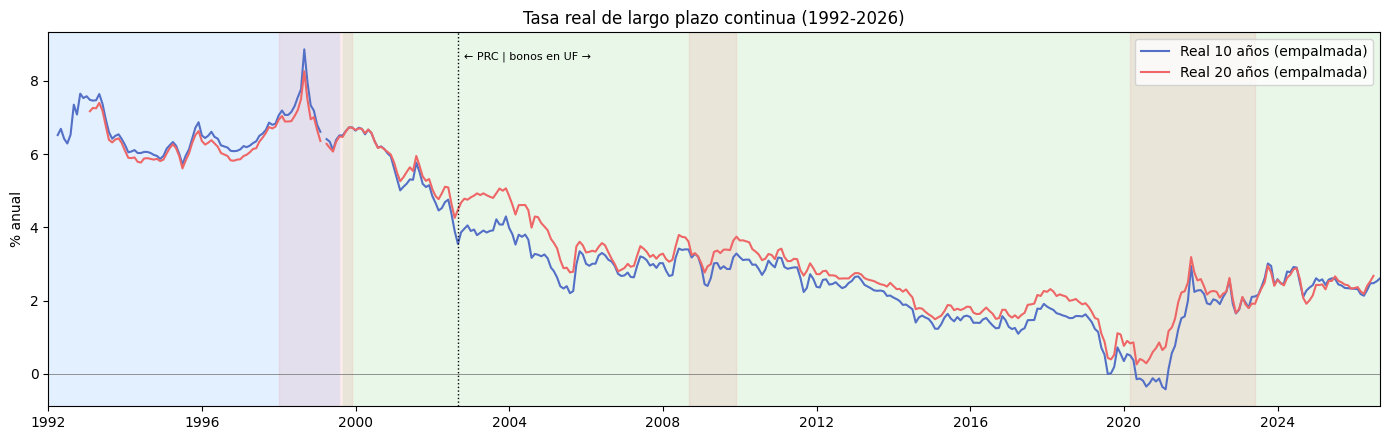

In [5]:
# Celda 4 — Arma dos tasas reales largas continuas empalmando PRC y bonos en UF:
# - a 20 años: PRC hasta ago-2002 + bono en UF desde sep-2002 (empalman sin hueco).
# - a 10 años: PRC hasta jul-2001 + bono en UF desde sep-2002; el hueco intermedio se rellena con el
#   promedio de los PRC a 8 y 20 años, corregido por la diferencia típica entre el PRC a 10 y ese promedio.
real_20 = tasas["PRC en UF a 20 años"].combine_first(tasas["Bono en UF a 20 años"])

prc_medio = (tasas["PRC en UF a 8 años"] + tasas["PRC en UF a 20 años"]) / 2
diferencia_10 = (tasas["PRC en UF a 10 años"] - prc_medio).dropna()
print(f"PRC10 - promedio(PRC8, PRC20): media {diferencia_10.mean():.3f}, desv. {diferencia_10.std():.3f} "
      f"({len(diferencia_10)} meses)")

real_10 = tasas["PRC en UF a 10 años"].combine_first(tasas["Bono en UF a 10 años"])
relleno = (prc_medio + diferencia_10.mean()).where(tasas.index >= pd.Timestamp("2001-08-01"))
real_10 = real_10.fillna(relleno)

tasas["Real 10 años (empalmada)"] = real_10
tasas["Real 20 años (empalmada)"] = real_20
print("Meses sin dato desde abr-1992 → real 10:", real_10.loc["1992-04":].isna().sum(),
      "| real 20 desde feb-1993:", real_20.loc["1993-02":].isna().sum())

fig, ax = plt.subplots(figsize=(14, 4.5))
fondo(ax)
ax.plot(tasas.index, real_10, label="Real 10 años (empalmada)", color="#5470c6")
ax.plot(tasas.index, real_20, label="Real 20 años (empalmada)", color="#ee6666")
ax.axvline(pd.Timestamp("2002-09-01"), color="black", linestyle=":", linewidth=1)
ax.text(pd.Timestamp("2002-11-01"), ax.get_ylim()[1] * 0.92, "← PRC | bonos en UF →", fontsize=8)
ax.set_xlim(pd.Timestamp("1992-01-01"), tasas.index.max())
ax.set_title("Tasa real de largo plazo continua (1992-2026)")
ax.set_ylabel("% anual")
ax.legend()
plt.tight_layout()
plt.show()

,meses,media,desv_estandar,p5,p95
Captación pesos 30-89d − TPM nominal,301.0,0.06,0.36,-0.51,0.64
Captación UF 90d-1a − TPM real,54.0,0.00,0.89,-0.63,1.35
Captación UF 90d-1a − PRBC 90d,174.0,-0.13,0.69,-0.64,0.56


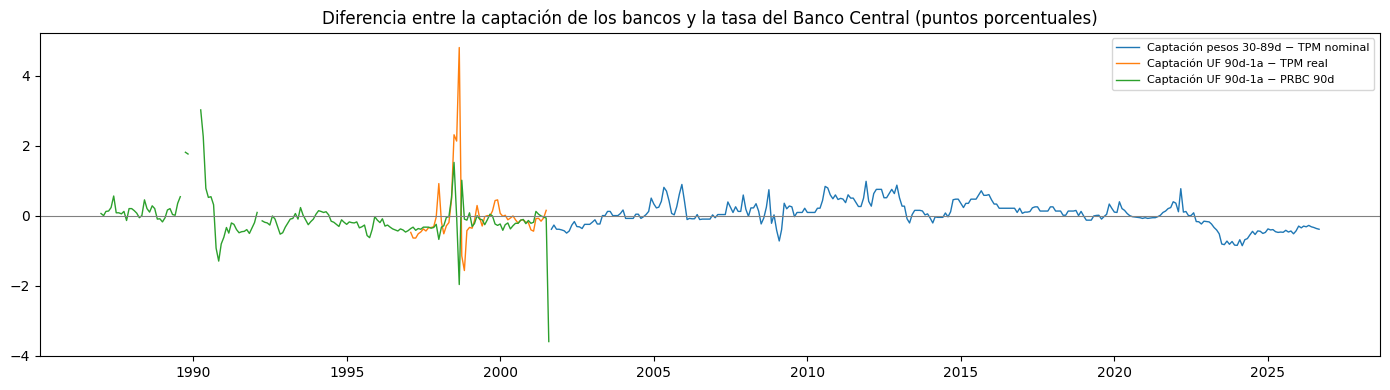

In [6]:
# Celda 5 — Compara la captación de los bancos con la tasa del Banco Central en los años en que hay ambas:
# - nominal: captación en pesos 30-89 días vs TPM nominal (2001-2026)
# - real: captación en UF 90 días-1 año vs TPM real (1997-2001) y vs PRBC 90 días (1987-2008)
# Si la diferencia es chica y estable, la captación sirve para estimar la tasa corta antes de 2001.
comparaciones = {
    "Captación pesos 30-89d − TPM nominal": tasas["Captación en pesos, 30 a 89 días"] - tasas["TPM nominal"],
    "Captación UF 90d-1a − TPM real": tasas["Captación en UF, 90 días a 1 año"] - tasas["TPM real"],
    "Captación UF 90d-1a − PRBC 90d": tasas["Captación en UF, 90 días a 1 año"] - tasas["PRBC en UF a 90 días"],
}
resumen = pd.DataFrame({
    nombre: {"meses": d.notna().sum(), "media": d.mean(), "desv_estandar": d.std(),
             "p5": d.quantile(0.05), "p95": d.quantile(0.95)}
    for nombre, d in comparaciones.items()
}).T.round(2)
display(resumen)

fig, ax = plt.subplots(figsize=(14, 4))
for nombre, d in comparaciones.items():
    ax.plot(d.index, d, label=nombre, linewidth=1)
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Diferencia entre la captación de los bancos y la tasa del Banco Central (puntos porcentuales)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [7]:
# Celda 6 — Persistencia por régimen monetario: estima un AR(1) mensual (tasa_t = a + b·tasa_{t-1})
# en cada régimen y calcula la vida media (meses que tarda en disiparse la mitad de un shock).
# b cerca de 1 = muy persistente (casi no vuelve a un promedio); b más bajo = vuelve rápido.
def ar1(serie):
    x = serie.dropna()
    if len(x) < 24:
        return np.nan, np.nan, len(x)
    b, a = np.polyfit(x.iloc[:-1].to_numpy(), x.iloc[1:].to_numpy(), 1)
    return b, a / (1 - b) if b < 1 else np.nan, len(x)


SERIES_PERSISTENCIA = ["Captación en pesos, 30 a 89 días", "Captación en UF, 90 días a 1 año",
                       "Real 10 años (empalmada)", "Real 20 años (empalmada)", "Inflación 12m"]
filas = []
for serie in SERIES_PERSISTENCIA:
    for desde, hasta, _, regimen in REGIMENES:
        b, media_largo_plazo, n = ar1(tasas.loc[desde:hasta, serie])
        vida_media = np.log(0.5) / np.log(b) if 0 < b < 1 else np.nan
        filas.append({"serie": serie, "régimen": regimen, "meses": n, "b": b,
                      "vida_media_meses": vida_media, "nivel_al_que_vuelve": media_largo_plazo})
persistencia = pd.DataFrame(filas).set_index(["serie", "régimen"]).round(3)
persistencia

meses      b  \
serie                            régimen                         
Captación en pesos, 30 a 89 días sin meta           108  0.718   
                                 metas parciales    104  0.627   
                                 metas plenas       325  0.965   
Captación en UF, 90 días a 1 año sin meta           108  0.880   
                                 metas parciales    104  0.860   
                                 metas plenas       325  0.839   
Real 10 años (empalmada)         sin meta             0    NaN   
                                 metas parciales     88  0.904   
                                 metas plenas       325  0.979   
Real 20 años (empalmada)         sin meta             0    NaN   
                                 metas parciales     78  0.909   
                                 metas plenas       323  0.982   
Inflación 12m                    sin meta           108  0.957   
                                 metas parciales    104  0.967   
                                 metas plenas       325  0.979   

                                                  vida_media_meses  \
serie                            régimen                             
Captación en pesos, 30 a 89 días sin meta                    2.088   
                                 metas parciales             1.484   
                                 metas plenas               19.369   
Captación en UF, 90 días a 1 año sin meta                    5.428   
                                 metas parciales             4.611   
                                 metas plenas                3.954   
Real 10 años (empalmada)         sin meta                      NaN   
                                 metas parciales             6.895   
                                 metas plenas               32.412   
Real 20 años (empalmada)         sin meta                      NaN   
                                 metas parciales             7.262   
                                 metas plenas               39.229   
Inflación 12m                    sin meta                   15.734   
                                 metas parciales            20.740   
                                 metas plenas               32.894   

                                                  nivel_al_que_vuelve  
serie                            régimen                               
Captación en pesos, 30 a 89 días sin meta                      24.836  
                                 metas parciales               14.224  
                                 metas plenas                   4.179  
Captación en UF, 90 días a 1 año sin meta                       6.729  
                                 metas parciales                6.435  
                                 metas plenas                   1.937  
Real 10 años (empalmada)         sin meta                         NaN  
                                 metas parciales                6.612  
                                 metas plenas                   2.085  
Real 20 años (empalmada)         sin meta                         NaN  
                                 metas parciales                6.287  
                                 metas plenas                   2.303  
Inflación 12m                    sin meta                      24.569  
                                 metas parciales                4.157  
                                 metas plenas                   3.991